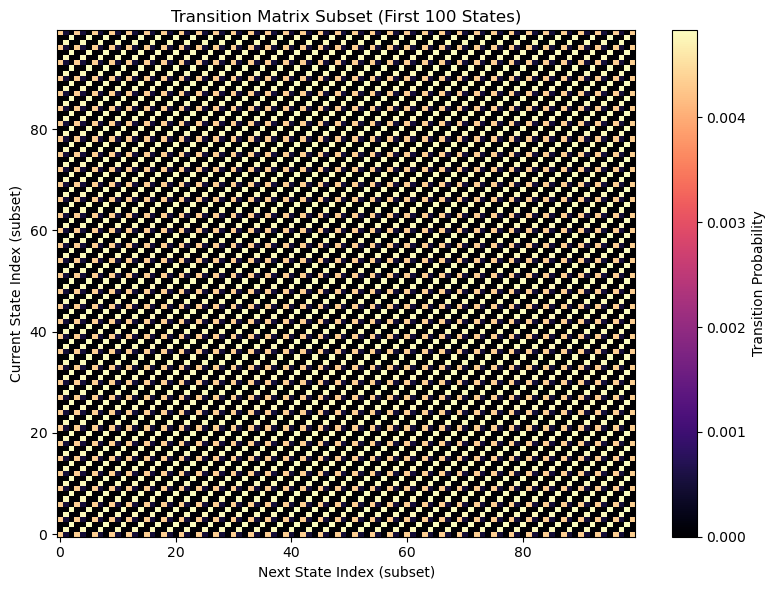

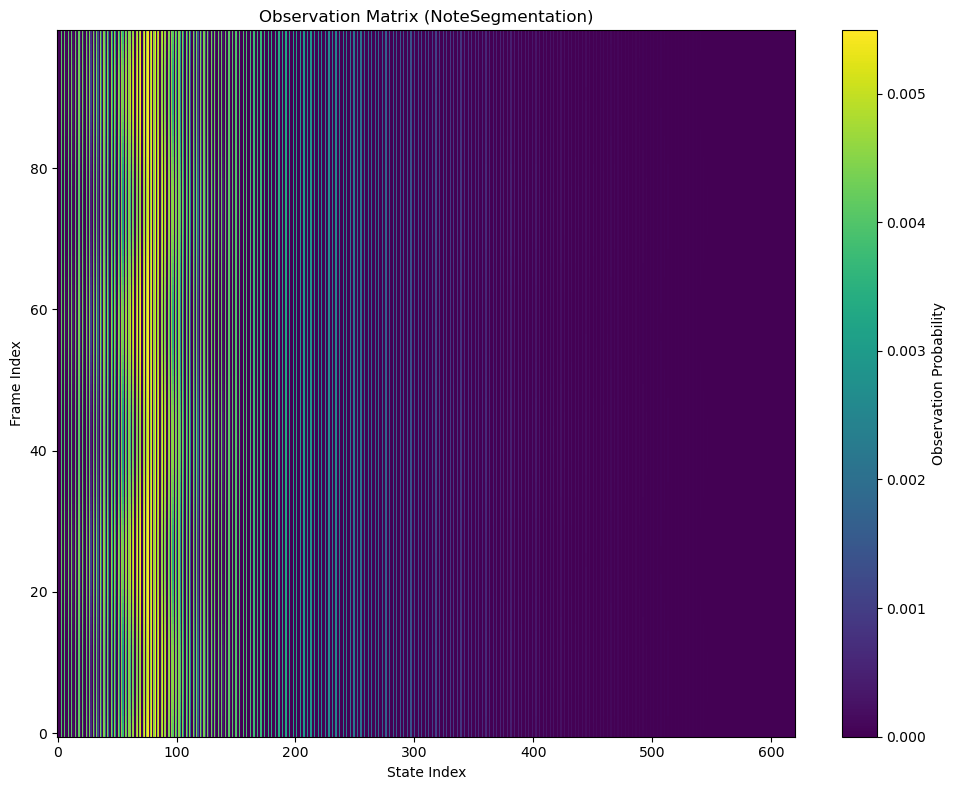

[79 79 79 79 82 82 82 82 82 82 82 82 82 82 79 79 79 76 76 76 73 73 73 73
 73 73 73 73 73 73 76 76 76 79 79 79 79 82 82 82 82 82 82 82 82 82 82 79
 79 79 76 76 76 73 73 73 73 73 73 73 73 73 73 76 76 76 79 79 79 79 82 82
 82 82 82 82 82 82 82 82 79 79 79 76 76 76 73 73 73 73 73 73 73 73 73 73
 76 76 76 79]


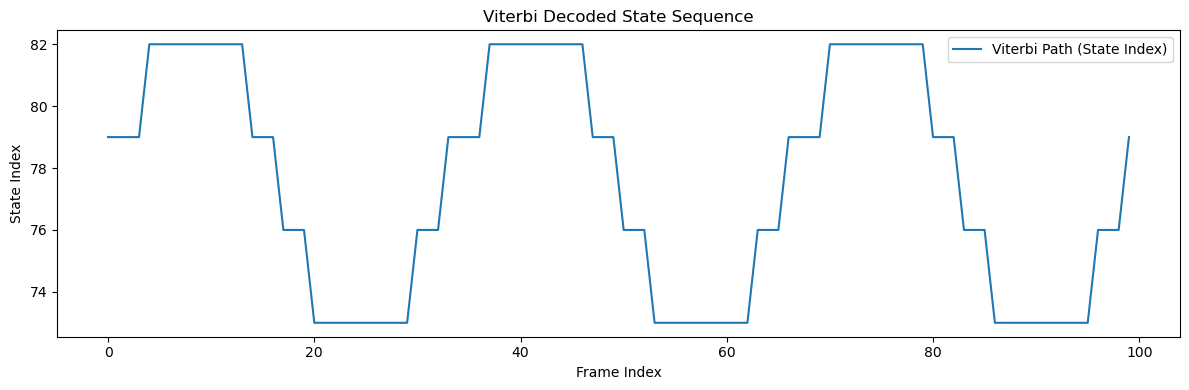

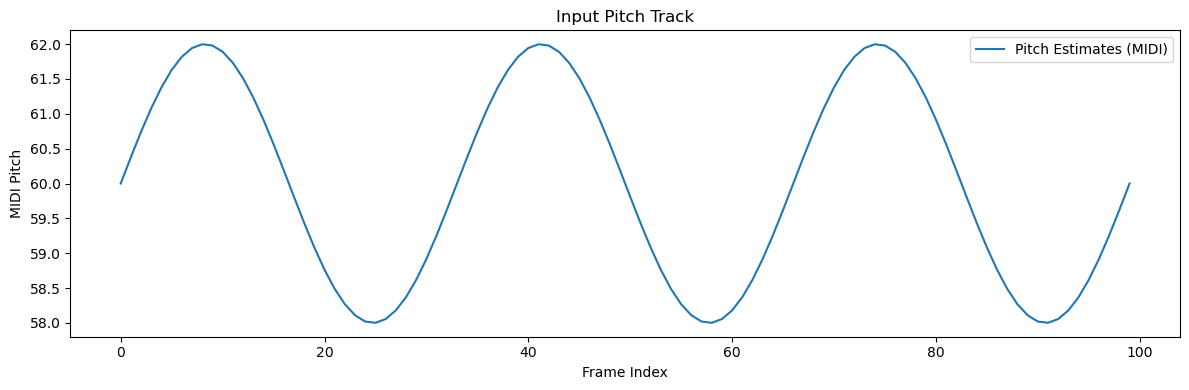

Frequency: 60.559, Start Time: 0.0, End Time: 0.09287981859410431
Frequency: 61.735, Start Time: 0.09287981859410431, End Time: 0.3250793650793651
Frequency: 60.559, Start Time: 0.3250793650793651, End Time: 0.3947392290249433
Frequency: 59.402, Start Time: 0.3947392290249433, End Time: 0.46439909297052157
Frequency: 58.27, Start Time: 0.46439909297052157, End Time: 0.6965986394557824
Frequency: 59.402, Start Time: 0.6965986394557824, End Time: 0.7662585034013606
Frequency: 60.559, Start Time: 0.7662585034013606, End Time: 0.8591383219954649
Frequency: 61.735, Start Time: 0.8591383219954649, End Time: 1.0913378684807256
Frequency: 60.559, Start Time: 1.0913378684807256, End Time: 1.1609977324263039
Frequency: 59.402, Start Time: 1.1609977324263039, End Time: 1.2306575963718822
Frequency: 58.27, Start Time: 1.2306575963718822, End Time: 1.4628571428571429
Frequency: 59.402, Start Time: 1.4628571428571429, End Time: 1.5325170068027212
Frequency: 60.559, Start Time: 1.5325170068027212, En

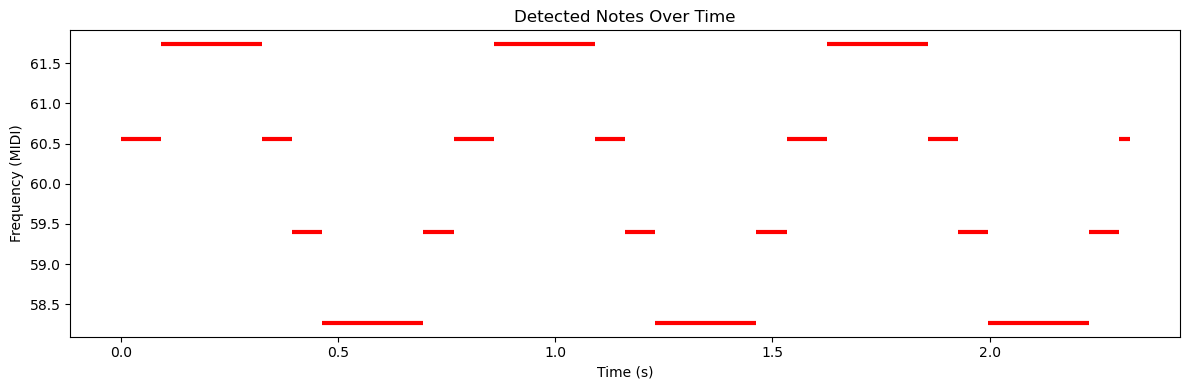

In [7]:
import numpy as np
# from util.audio import midi_to_hz
import matplotlib.pyplot as plt
import sys
import os

project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
if project_root not in sys.path:
    sys.path.append(project_root)

from modules.NoteSegmentation import NoteSegmentation

n_frames = 100
pitch_estimates = 60 + 2 * np.sin(np.linspace(0, 6 * np.pi, n_frames))  # MIDI numbers
note_seg = NoteSegmentation()

# Plot transition matrix
# trans_matrix = note_seg._build_transition_matrix()
# plt.figure(figsize=(10, 8))
# plt.imshow(trans_matrix, aspect='auto', origin='lower', interpolation='nearest', cmap='magma')
# plt.colorbar(label='Transition Probability')
# plt.xlabel('Next State Index')
# plt.ylabel('Current State Index')
# plt.title('Transition Matrix (NoteSegmentation)')
# plt.tight_layout()
# plt.show()
trans_matrix = note_seg._build_transition_matrix()
# Plot a subset of the transition matrix for better visibility
subset_size = 100  # Number of states to show (change as needed)
plt.figure(figsize=(8, 6))
plt.imshow(trans_matrix[:subset_size, :subset_size], aspect='auto', origin='lower', interpolation='nearest', cmap='magma')
plt.colorbar(label='Transition Probability')
plt.xlabel('Next State Index (subset)')
plt.ylabel('Current State Index (subset)')
plt.title(f'Transition Matrix Subset (First {subset_size} States)')
plt.tight_layout()
plt.show()

# Plot observation matrix if implemented
try:
    obs_matrix = note_seg._build_observation_matrix(pitch_estimates)
    if obs_matrix is not None:
        plt.figure(figsize=(10, 8))
        plt.imshow(obs_matrix, aspect='auto', origin='lower', interpolation='nearest', cmap='viridis')
        plt.colorbar(label='Observation Probability')
        plt.xlabel('State Index')
        plt.ylabel('Frame Index')
        plt.title('Observation Matrix (NoteSegmentation)')
        plt.tight_layout()
        plt.show()
except Exception as e:
    print("Observation matrix plotting skipped (not implemented):", e)

# Plot Viterbi trellis if implemented
# Plot Viterbi path (state sequence) if available
viterbi = note_seg._viterbi_decoding(pitch_estimates)
if viterbi is not None:
    plt.figure(figsize=(12, 4))
    plt.plot(viterbi, label='Viterbi Path (State Index)')
    plt.xlabel('Frame Index')
    plt.ylabel('State Index')
    plt.title('Viterbi Decoded State Sequence')
    plt.legend()
    plt.tight_layout()
    plt.show()

# Plot pitch track
plt.figure(figsize=(12, 4))
plt.plot(pitch_estimates, label='Pitch Estimates (MIDI)')
plt.xlabel('Frame Index')
plt.ylabel('MIDI Pitch')
plt.title('Input Pitch Track')
plt.legend()
plt.tight_layout()
plt.show()

# Plot the result of post-processing if implemented in NoteSegmentation

post_processed = note_seg.post_process(viterbi)
# Print frequency, start time, and end time for each post-processed note
for note in post_processed:
    print(f"Frequency: {note['frequency'].round(3)}, Start Time: {note['start_time']}, End Time: {note['end_time']}")
# Plot notes as horizontal lines over time
plt.figure(figsize=(12, 4))
for note in post_processed:
    plt.hlines(note['frequency'], note['start_time'], note['end_time'], colors='r', linewidth=3)
plt.xlabel('Time (s)')
plt.ylabel('Frequency (MIDI)')
plt.title('Detected Notes Over Time')
plt.tight_layout()
plt.show()
